# Placement strategies and requirements

This notebook shows how the ECLYPSE placement strategies behave on a `Network`, when the
requirements of the services are checked against the resources of the nodes, and what
`HostOnlyStrategy` adds.

**Placement.** At every step ECLYPSE asks the placement strategy of an application where
to run its services, and checks the answer against the resources of the nodes (the
*audit*). A placement that violates a requirement is discarded, and the application is
placed again at the next step: in between, its services run nowhere.

**Requirements are checked only for assets.** A requirement such as `cpu=4` is compared
with the `cpu` of a node only if `cpu` is an *asset*, declared on both the network and
the application. Without assets every placement passes the audit. Here we use the
default assets of ECLYPSE (`include_default_assets=True`):

| Asset | On | Requirement satisfied when | Along a path |
|---|---|---|---|
| `cpu`, `ram`, `storage`, `gpu` | nodes | node ≥ requirement (consumed by every service) | – |
| `availability` | nodes | node ≥ requirement; a node with 0 is down | – |
| `processing_time` | nodes | never checked (non-functional) | – |
| `latency` | links | path ≤ requirement | sum of the links |
| `bandwidth` | links | path ≥ requirement | minimum of the links |

**The strategies** (in `eclypse.placement.strategies`):

- `FirstFitStrategy`: each service goes to the first node, in random order, whose residual
  resources satisfy its requirements;
- `BestFitStrategy`: each service goes to the node with the smallest residual resources
  that still satisfy its requirements;
- `RandomStrategy`: each service goes to a random node, **ignoring** the requirements;
- `RoundRobinStrategy`: the services go to the nodes in turn, **ignoring** the
  requirements.

None of them knows that, in a `Network`, routers forward traffic and only hosts run
services. `HostOnlyStrategy(strategy)` (in `eclypse.network`) wraps any strategy and
shows it only the hosts. A service placed on a router does not send traffic: its packets
are discarded and counted in `Network.router_source_packets`.

## Setup

In [1]:
import random
import shutil

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch

from eclypse.builders.network import get_network_scale_free
from eclypse.network import (
    HostOnlyStrategy,
    NetworkApplication,
    PacketGenerationEvent,
    RoutingEvent,
)
from eclypse.placement.strategies import (
    BestFitStrategy,
    FirstFitStrategy,
    RandomStrategy,
    RoundRobinStrategy,
)
from eclypse.simulation import Simulation, SimulationConfig
from eclypse.utils.defaults import get_default_sim_path

SEED = 42
RESULTS = get_default_sim_path() / "demo_placement_strategies"
# ECLYPSE writes to a new timestamped folder if the path exists: start from a clean one
shutil.rmtree(RESULTS, ignore_errors=True)

# Chart style: light surface, recessive axes and grid
SURFACE, TEXT, TEXT_MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
BLUE, ORANGE, AQUA, YELLOW, NEUTRAL = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#c3c2b7"
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": TEXT_MUTED,
    "axes.titlecolor": TEXT,
    "axes.titleweight": "bold",
    "axes.titlesize": 13,
    "axes.grid": True,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "xtick.color": TEXT_MUTED,
    "ytick.color": TEXT_MUTED,
    "legend.frameon": False,
    "legend.labelcolor": TEXT,
    "font.size": 10,
})
RAMP = LinearSegmentedColormap.from_list(
    "blue_ramp", ["#b7d3f6", "#6da7ec", "#2a78d6", "#1c5cab", "#0d366b"]
)

## 1. The network, with the default assets

A scale-free network of 10 routers with one host each, built with
`include_default_assets=True`. The hosts get different resources, so that the strategies
have something to choose: in turn 2, 4, 8 and 16 CPUs, and twice as much RAM.

`resource_init` sets the value of every asset that is **not** passed explicitly: `"max"`
gives it its best value (1e9 CPUs, availability 1), `"min"` its worst one (0 CPUs,
availability 0, so the node is down). The builders use `"min"` by default: section 6
shows what happens then. Routers get 0 CPUs and 0 RAM from `add_router`.

In [2]:
CPU_SIZES = [2, 4, 8, 16]  # CPUs of the hosts, in turn; the RAM is twice the CPUs


def build_network(resource_init="max"):
    net = get_network_scale_free(
        10, 2, hosts_per_router=1, seed=SEED,
        include_default_assets=True, resource_init=resource_init,
    )
    for i, host in enumerate(net.hosts):
        net.nodes[host]["cpu"] = CPU_SIZES[i % len(CPU_SIZES)]
        net.nodes[host]["ram"] = 2 * CPU_SIZES[i % len(CPU_SIZES)]
    return net


net = build_network()
ASSETS = ["cpu", "ram", "storage", "gpu", "availability", "processing_time"]
nodes = pd.DataFrame(
    [{"node": n, **{a: net.nodes[n][a] for a in ASSETS}} for n in [*net.hosts[:4], net.routers[0]]]
).set_index("node")
print("Node assets (the first four hosts and a router)")
print(nodes.to_string(float_format=lambda x: f"{x:g}"))

u, v = net.hosts[0], net.nodes[net.hosts[0]]["router"]
print(f"\nLink assets of {u} -> {v}: "
      f"latency {net.edges[u, v]['latency']:g} ms, bandwidth {net.edges[u, v]['bandwidth']:g}")

Node assets (the first four hosts and a router)
          cpu  ram  storage   gpu  availability  processing_time
node                                                            
host_0_0    2    4    1e+09 1e+09             1           0.0001
host_1_0    4    8    1e+09 1e+09             1           0.0001
host_2_0    8   16    1e+09 1e+09             1           0.0001
host_3_0   16   32    1e+09 1e+09             1           0.0001
router_0    0    0    1e+09 1e+09             1           0.0001

Link assets of host_0_0 -> router_0: latency 0 ms, bandwidth 1e+09


`storage` and `gpu` were not passed, so they are 1e9: with `"max"`, an asset you forget
never constrains anything. The `latency` of the links starts at 0 and is updated by the
network at every step with the measured delays; `bandwidth` (the asset) is not the
`bandwidth_mbps` used by the delay model, and stays at 1e9.

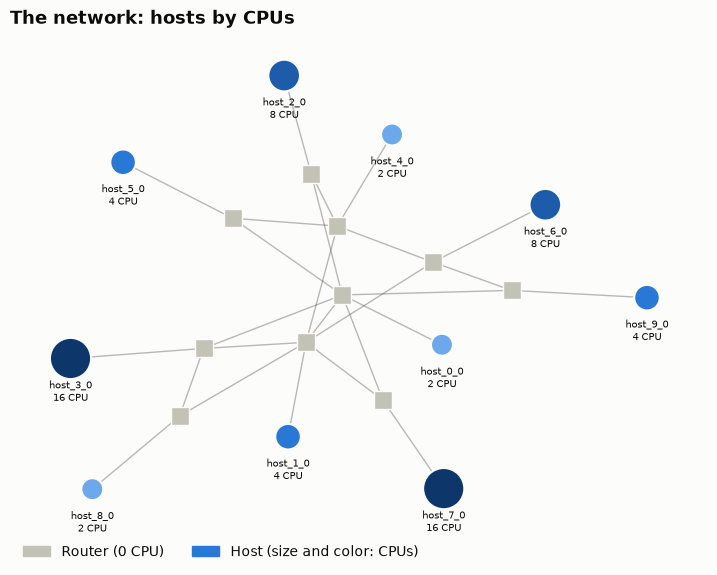

In [3]:
def plain_graph(network):
    # Undirected networkx copy of a Network, used for the layout and the drawing
    graph = nx.Graph()
    graph.add_nodes_from(network.nodes)
    graph.add_edges_from((u, v) for u, v in network.edges)
    return graph


graph = plain_graph(net)
layout = nx.spring_layout(graph, k=0.6, iterations=200, seed=SEED)
cpu = {h: net.nodes[h]["cpu"] for h in net.hosts}

fig, ax = plt.subplots(figsize=(9, 6.5))
nx.draw_networkx_edges(graph, layout, ax=ax, width=1, edge_color=TEXT_MUTED, alpha=0.4)
nx.draw_networkx_nodes(graph, layout, nodelist=net.routers, ax=ax, node_size=180,
                       node_color=NEUTRAL, node_shape="s", edgecolors=SURFACE, linewidths=1)
nx.draw_networkx_nodes(graph, layout, nodelist=net.hosts, ax=ax,
                       node_size=[160 + 45 * cpu[h] for h in net.hosts],
                       node_color=[RAMP(np.log2(cpu[h]) / 4) for h in net.hosts],
                       edgecolors=SURFACE, linewidths=1.5)
label_pos = {h: (x, y - 0.09) for h, (x, y) in layout.items()}
nx.draw_networkx_labels(graph, label_pos, ax=ax, font_size=7.5, font_color=TEXT,
                        labels={h: f"{h}\n{cpu[h]} CPU" for h in net.hosts},
                        verticalalignment="top")
ax.legend(handles=[Patch(color=NEUTRAL, label="Router (0 CPU)"),
                   Patch(color=RAMP(0.5), label="Host (size and color: CPUs)")],
          loc="upper left", bbox_to_anchor=(0, 0), ncol=2)
ax.set_title("The network: hosts by CPUs", loc="left")
ax.axis("off")
plt.show()

## 2. The application

An online shop with six services. `requirement_init="min"` gives every requirement that
is not passed its least demanding value (0 storage, availability 0, latency 1e9), so
only CPU and RAM matter. `monitor` requires nothing at all: every node, routers
included, can run it.

In [4]:
SERVICES = {  # service: (CPUs, RAM)
    "frontend": (2, 4),
    "auth": (1, 2),
    "catalog": (4, 8),
    "orders": (4, 8),
    "db": (8, 16),
    "monitor": (0, 0),
}
FLOWS = [("frontend", "auth"), ("frontend", "catalog"), ("frontend", "orders"),
         ("catalog", "db"), ("orders", "db"), ("monitor", "db")]


def build_application(update_policies=None, packets_per_step=2.0):
    app = NetworkApplication(
        "Shop", include_default_assets=True, requirement_init="min",
        update_policies=update_policies,
    )
    for service, (cpus, ram) in SERVICES.items():
        app.add_node(service, cpu=cpus, ram=ram)
    for src, dst in FLOWS:
        app.add_edge(src, dst, packet_size_bytes=1000, avg_packets_per_step=packets_per_step)
    return app


app = build_application()
requirements = pd.DataFrame(
    [{"service": s, "cpu": app.nodes[s]["cpu"], "ram": app.nodes[s]["ram"],
      "availability": app.nodes[s]["availability"]} for s in app.nodes]
).set_index("service")
print(requirements.to_string(float_format=lambda x: f"{x:g}"))
print(f"\nTotal: {requirements['cpu'].sum()} CPUs; the hosts have {sum(cpu.values())}.")

14:52:53.808 | INFO | Shop - Added flow frontend->auth, 2.0 pkt/step (avg), size 1000B
          cpu  ram  availability
service                         
frontend    2    4             0
auth        1    2             0
catalog     4    8             0
orders      4    8             0
db          8   16             0
monitor     0    0             0

Total: 19 CPUs; the hosts have 66.
14:52:53.809 | INFO | Shop - Added flow frontend->catalog, 2.0 pkt/step (avg), size 1000B
14:52:53.809 | INFO | Shop - Added flow frontend->orders, 2.0 pkt/step (avg), size 1000B
14:52:53.809 | INFO | Shop - Added flow catalog->db, 2.0 pkt/step (avg), size 1000B
14:52:53.809 | INFO | Shop - Added flow orders->db, 2.0 pkt/step (avg), size 1000B
14:52:53.810 | INFO | Shop - Added flow monitor->db, 2.0 pkt/step (avg), size 1000B


## 3. Simulation helpers

`run` simulates the application on a fresh network with a placement strategy, and
records at every step the placement and the fate of the packets:

- `delivered`: packets delivered to their destination service;
- `router_source`: packets of a service placed on a router (discarded);
- `unplaced`: packets generated while the application had no placement (discarded);
- `misdelivered`: packets that reached a node after their destination service had left
  it (discarded).

The packets still travelling at the end of the simulation make up the rest.

In [5]:
COUNTERS = ["router_source", "unplaced", "misdelivered"]


class CountingGeneration(PacketGenerationEvent):
    """Packet generation that also counts the generated packets."""

    def __init__(self):
        super().__init__()
        self.generated = 0

    def __call__(self, app, placement, infra, **kwargs):
        out = super().__call__(app, placement, infra, **kwargs)
        self.generated += app.num_generated
        return out


class RecordingRouting(RoutingEvent):
    """Routing that records, at every step, the placement and the fate of the packets."""

    def __init__(self, step_duration_s):
        super().__init__(step_duration_s=step_duration_s)
        self.rows = []

    def route(self, applications, infra, step=None):
        before = {c: getattr(infra, f"{c}_packets") for c in COUNTERS}
        delivered = 0
        forward = infra.forward_batch

        def counted(batch, now):  # count the packets delivered in this step
            nonlocal delivered
            out = forward(batch, now)
            delivered += len(out)
            return out

        infra.forward_batch = counted
        try:
            super().route(applications, infra, step)
        finally:
            del infra.forward_batch  # back to the method of the class
        _, placement = applications[0]
        self.rows.append({
            "step": len(self.rows) + 1,
            "mapping": dict(placement.mapping),
            "delivered": delivered,
            **{c: getattr(infra, f"{c}_packets") - before[c] for c in COUNTERS},
        })


def run(name, strategy, steps=30, step_duration_s=0.001, network=None, application=None):
    random.seed(SEED)
    np.random.seed(SEED)
    network = network or build_network()
    application = application or build_application()
    generation, routing = CountingGeneration(), RecordingRouting(step_duration_s)
    config = SimulationConfig(
        seed=SEED, max_steps=steps, path=RESULTS / name,
        events=[generation, routing], include_default_metrics=False, log_level="ERROR",
    )
    sim = Simulation(network, simulation_config=config)
    sim.register(application, placement_strategy=strategy)
    sim.start()
    sim.wait()
    return network, generation.generated, pd.DataFrame(routing.rows)

## 4. The strategies, with and without `HostOnlyStrategy`

Every strategy runs for 30 steps of 1 ms, once on its own and once wrapped in
`HostOnlyStrategy`. For every run the table shows the final placement and how many
steps the application had one, whether the placement respects the CPUs of the hosts,
and the fate of the packets.

In [6]:
STRATEGIES = {
    "FirstFit": lambda: FirstFitStrategy(),
    "BestFit": lambda: BestFitStrategy(),
    "Random": lambda: RandomStrategy(seed=SEED),
    "RoundRobin": lambda: RoundRobinStrategy(),
}


def cpu_respected(network, mapping):
    used = {}
    for service, node in mapping.items():
        used[node] = used.get(node, 0) + SERVICES[service][0]
    return all(cpus <= network.nodes[node]["cpu"] for node, cpus in used.items())


runs = {}
summary = []
for name, make in STRATEGIES.items():
    for host_only in (False, True):
        label = f"HostOnly({name})" if host_only else name
        strategy = HostOnlyStrategy(make()) if host_only else make()
        network, generated, steps = run(label, strategy)
        final = steps["mapping"].iloc[-1]
        runs[label] = (network, final)
        totals = steps[["delivered", *COUNTERS]].sum()
        summary.append({
            "run": label,
            "steps placed": int((steps["mapping"].map(len) > 0).sum()),
            "on routers": ", ".join(s for s, n in final.items() if n in network.routers) or "-",
            "cpu respected": cpu_respected(network, final) if final else "-",
            "generated": generated,
            **totals.to_dict(),
            "in transit": generated - totals.sum(),
        })

summary = pd.DataFrame(summary).set_index("run")
print(summary.to_string())

14:52:54.061 | INFO | Shop - Added flow frontend->auth, 2.0 pkt/step (avg), size 1000B
14:52:54.062 | INFO | Shop - Added flow frontend->catalog, 2.0 pkt/step (avg), size 1000B
14:52:54.062 | INFO | Shop - Added flow frontend->orders, 2.0 pkt/step (avg), size 1000B
14:52:54.062 | INFO | Shop - Added flow catalog->db, 2.0 pkt/step (avg), size 1000B
14:52:54.062 | INFO | Shop - Added flow orders->db, 2.0 pkt/step (avg), size 1000B
14:52:54.062 | INFO | Shop - Added flow monitor->db, 2.0 pkt/step (avg), size 1000B
                      steps placed on routers cpu respected  generated  delivered  router_source  unplaced  misdelivered  in transit
run                                                                                                                                 
FirstFit                        30    monitor          True        358        274             70         0             0          14
HostOnly(FirstFit)              30          -          True        358        314   

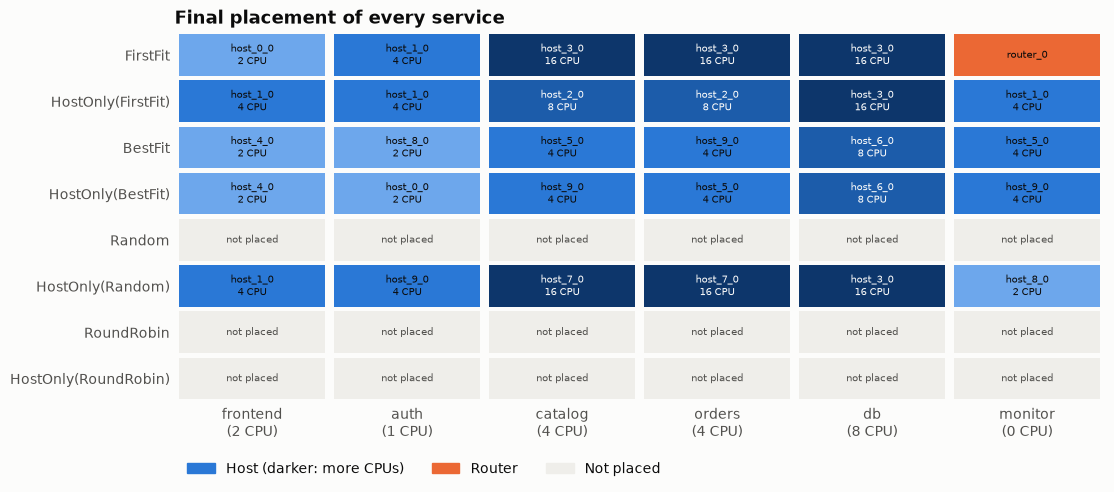

In [7]:
labels = list(runs)
services = list(SERVICES)
ROUTER_COLOR, UNPLACED_COLOR = ORANGE, "#efeeea"

fig, ax = plt.subplots(figsize=(12, 4.8))
for i, label in enumerate(labels):
    network, mapping = runs[label]
    for j, service in enumerate(services):
        node = mapping.get(service)
        if node is None:
            color, text, ink = UNPLACED_COLOR, "not placed", TEXT_MUTED
        elif node in network.routers:
            color, text, ink = ROUTER_COLOR, node, TEXT
        else:
            cpus = network.nodes[node]["cpu"]
            color, text = RAMP(np.log2(cpus) / 4), f"{node}\n{cpus} CPU"
            ink = SURFACE if cpus >= 8 else TEXT
        ax.add_patch(plt.Rectangle((j + 0.03, i + 0.05), 0.94, 0.9, color=color, lw=0))
        ax.text(j + 0.5, i + 0.5, text, ha="center", va="center", fontsize=7.5, color=ink)
ax.set_xlim(0, len(services))
ax.set_ylim(len(labels), 0)
ax.set_xticks(np.arange(len(services)) + 0.5, [f"{s}\n({SERVICES[s][0]} CPU)" for s in services])
ax.set_yticks(np.arange(len(labels)) + 0.5, labels)
ax.tick_params(length=0)
ax.grid(False)
for side in ax.spines.values():
    side.set_visible(False)
ax.legend(handles=[Patch(color=RAMP(0.5), label="Host (darker: more CPUs)"),
                   Patch(color=ROUTER_COLOR, label="Router"),
                   Patch(color=UNPLACED_COLOR, label="Not placed")],
          loc="upper left", bbox_to_anchor=(0, -0.13), ncol=3)
ax.set_title("Final placement of every service", loc="left")
plt.show()

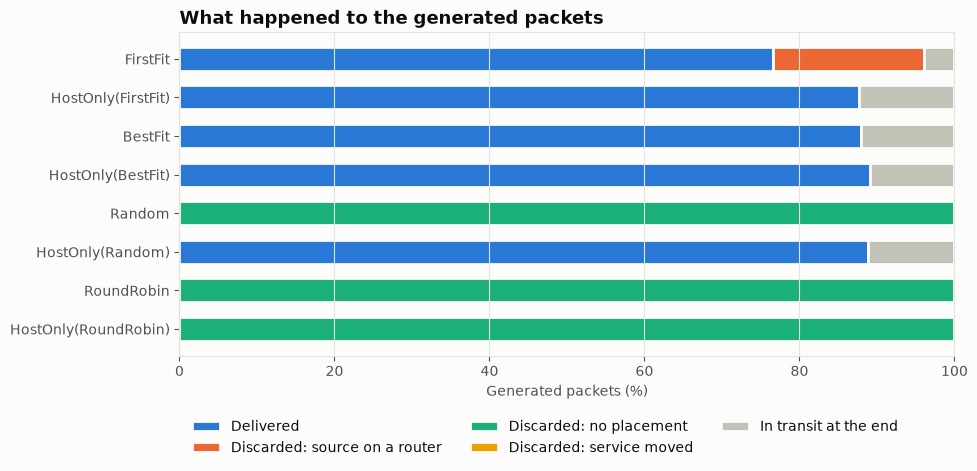

In [8]:
FATES = {  # fate: (color, label)
    "delivered": (BLUE, "Delivered"),
    "router_source": (ORANGE, "Discarded: source on a router"),
    "unplaced": (AQUA, "Discarded: no placement"),
    "misdelivered": (YELLOW, "Discarded: service moved"),
    "in transit": (NEUTRAL, "In transit at the end"),
}

fig, ax = plt.subplots(figsize=(10, 4.2))
y = np.arange(len(summary))
left = np.zeros(len(summary))
for fate, (color, label) in FATES.items():
    share = 100 * summary[fate].to_numpy() / summary["generated"].to_numpy()
    ax.barh(y, share, left=left, color=color, height=0.62, label=label,
            edgecolor=SURFACE, linewidth=2)
    left += share
ax.set_yticks(y, summary.index)
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel("Generated packets (%)")
ax.grid(axis="y", visible=False)
ax.legend(loc="upper left", bbox_to_anchor=(0, -0.16), ncol=3)
ax.set_title("What happened to the generated packets", loc="left")
plt.show()

**Reading the results.**

- **FirstFit and BestFit** respect the requirements: no host gets more CPUs than it has.
  Without the wrapper, though, `monitor` requires nothing, so a router satisfies it: in
  this run FirstFit puts it on a router, and all its packets are discarded as
  `router_source`. The requirements cannot prevent this, because a router *does* have
  the resources that `monitor` asks for. `HostOnlyStrategy` does.
- **Random** ignores the requirements. Without the wrapper it picks among routers and
  hosts, nearly always puts some service on a router (0 CPUs) or on a host that is too
  small, and the audit discards the placement: the application is placed again at
  every step and never runs, and every packet is `unplaced`. Restricted to the hosts,
  it finds a valid placement.
- **RoundRobin** ignores the requirements too, and it is deterministic: it gives the
  services to the nodes in order, so it proposes the same invalid placement at every
  step. Without the wrapper the first nodes are routers; with it, `db` (8 CPUs) gets a
  host with 2 CPUs. The application never runs in either case.

So the two mechanisms are complementary: the assets make the audit reject placements
that do not fit, and `HostOnlyStrategy` keeps services away from routers, which the
assets alone cannot always do.

## 5. Requirements that change during the simulation

An update policy raises the requirement of `catalog` from 4 to 12 CPUs at step 40.
Its host no longer fits, so the audit discards the placement of the whole application,
and FirstFit places it again at the next step, on other hosts.

Steps last 0.1 ms here, so packets need several steps to reach their destination
(each flow sends 0.5 packets per step, i.e. 5000 packets per second): when the
placement changes, some of them are still travelling towards hosts that no longer
run their destination service, and are counted as `misdelivered`.

In [9]:
class RaiseCpu:
    """Update policy: from step `at`, `service` requires `cpus` CPUs."""

    def __init__(self, at, service, cpus):
        self.at, self.service, self.cpus, self.step = at, service, cpus, 0

    def __call__(self, graph):
        self.step += 1
        if self.step == self.at:
            graph.nodes[self.service]["cpu"] = self.cpus


CHANGE_AT = 40
network, generated, steps = run(
    "requirement_change", HostOnlyStrategy(FirstFitStrategy()), steps=100,
    step_duration_s=0.0001,
    application=build_application([RaiseCpu(CHANGE_AT, "catalog", 12)], packets_per_step=0.5),
)

previous = None
for row in steps.itertuples():
    if row.mapping != previous:
        print(f"step {row.step:2d}: {row.mapping or 'no placement'}")
        previous = row.mapping
totals = steps[["delivered", *COUNTERS]].sum()
print(f"\nGenerated {generated}: " + ", ".join(f"{k} {v}" for k, v in totals.items())
      + f", in transit {generated - totals.sum()}")

step  1: {'frontend': 'host_1_0', 'auth': 'host_1_0', 'catalog': 'host_2_0', 'orders': 'host_2_0', 'db': 'host_3_0', 'monitor': 'host_1_0'}
step 41: no placement
step 42: {'frontend': 'host_3_0', 'auth': 'host_3_0', 'catalog': 'host_3_0', 'orders': 'host_9_0', 'db': 'host_2_0', 'monitor': 'host_3_0'}

Generated 294: delivered 250, router_source 0, unplaced 3, misdelivered 23, in transit 18


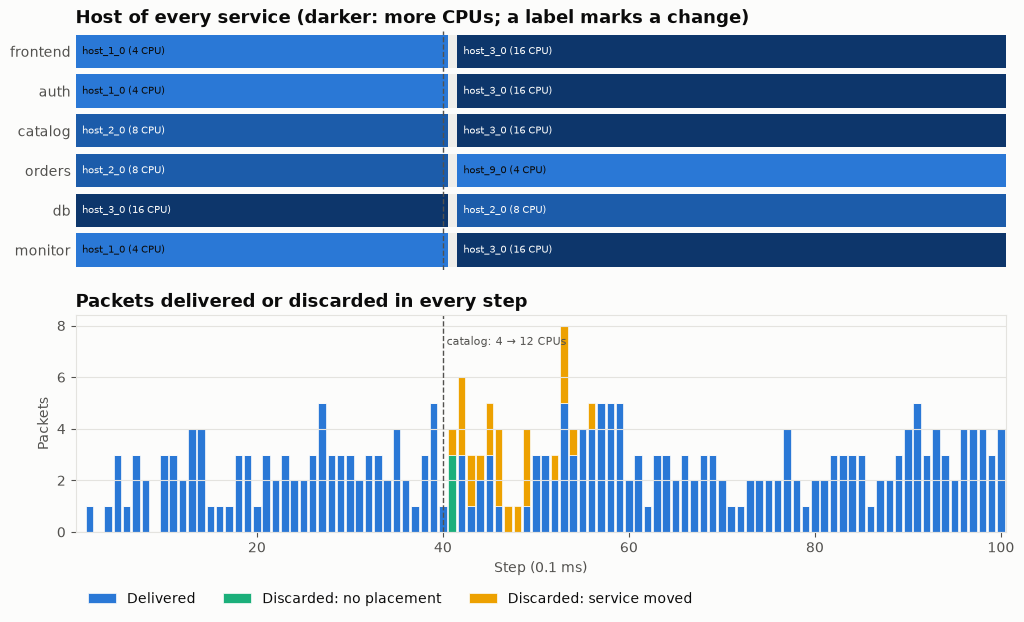

In [10]:
fig, (ax_map, ax_fate) = plt.subplots(
    2, 1, figsize=(12, 6.5), sharex=True, gridspec_kw={"height_ratios": [1.1, 1]}
)

# Top: the host of every service, step by step
for j, service in enumerate(services):
    for row in steps.itertuples():
        node = row.mapping.get(service)
        if node is None:
            color = UNPLACED_COLOR
        else:
            color = RAMP(np.log2(network.nodes[node]["cpu"]) / 4)
        ax_map.add_patch(plt.Rectangle((row.step - 0.5, j + 0.08), 1, 0.84, color=color, lw=0))
    for row in steps.itertuples():  # label the host at the start and at every change
        node = row.mapping.get(service)
        before = steps["mapping"].iloc[row.step - 2].get(service) if row.step > 1 else None
        if node is not None and node != before:
            cpus = network.nodes[node]["cpu"]
            ax_map.text(row.step + 0.2, j + 0.5, f"{node} ({cpus} CPU)", va="center",
                        fontsize=7.5, color=SURFACE if cpus >= 8 else TEXT)
ax_map.set_ylim(len(services), 0)
ax_map.set_yticks(np.arange(len(services)) + 0.5, services)
ax_map.tick_params(length=0)
ax_map.grid(False)
for side in ax_map.spines.values():
    side.set_visible(False)
ax_map.set_title("Host of every service (darker: more CPUs; a label marks a change)", loc="left")

# Bottom: the fate of the packets, step by step
bottom = np.zeros(len(steps))
for fate in ["delivered", *COUNTERS]:
    if not steps[fate].any():
        continue
    color, label = FATES[fate]
    ax_fate.bar(steps["step"], steps[fate], bottom=bottom, width=0.8, color=color,
                label=label, edgecolor=SURFACE, linewidth=0.5)
    bottom += steps[fate].to_numpy()
for ax in (ax_map, ax_fate):
    ax.axvline(CHANGE_AT, color=TEXT_MUTED, lw=1, ls="--")
ax_fate.text(CHANGE_AT + 0.4, bottom.max() * 0.95, "catalog: 4 → 12 CPUs", fontsize=8,
             color=TEXT_MUTED, va="top")
ax_fate.set_xlim(0.5, len(steps) + 0.5)
ax_fate.set_xlabel("Step (0.1 ms)")
ax_fate.yaxis.get_major_locator().set_params(integer=True)
ax_fate.set_ylabel("Packets")
ax_fate.grid(axis="x", visible=False)
ax_fate.legend(loc="upper left", bbox_to_anchor=(0, -0.22), ncol=4)
ax_fate.set_title("Packets delivered or discarded in every step", loc="left")
plt.show()

The step after the change has no placement: the packets generated then are `unplaced`.
In the following steps the packets that were travelling towards the old hosts arrive
there and are `misdelivered`. ECLYPSE places the whole application again, not only
`catalog`, so all the services may move.

## 6. The trap of `resource_init="min"`

The same network, built with `resource_init="min"`, the default of the builders.
`availability` is not passed, so it gets its worst value, 0: every node is down,
FirstFit finds no node, and no packet is ever delivered. There is no error: only the
counters show it.

In [11]:
down_net = build_network(resource_init="min")
sample = [*down_net.hosts[:3], down_net.routers[0]]
print("availability:", {n: down_net.nodes[n]["availability"] for n in sample})
up = sum(down_net.is_available(n) for n in down_net.nodes)
print("nodes up:", up, "of", down_net.number_of_nodes())

network, generated, steps = run("resource_init_min", HostOnlyStrategy(FirstFitStrategy()),
                                steps=10, network=down_net)
print(f"\nsteps placed: {(steps['mapping'].map(len) > 0).sum()} of {len(steps)}")
print(f"generated {generated}, delivered {steps['delivered'].sum()}, "
      f"unplaced {steps['unplaced'].sum()}")

availability: {'host_0_0': 0.0, 'host_1_0': 0.0, 'host_2_0': 0.0, 'router_0': 0.0}
nodes up: 0 of 20

steps placed: 0 of 10
generated 116, delivered 0, unplaced 116


## Notes

- **Assets on both sides.** A requirement is checked only if the asset is declared on
  the network *and* on the application. To check only some resources, declare only
  those assets, e.g. `node_assets={"cpu": cpu(init_fn_or_value=0), "ram": ram(init_fn_or_value=0)}`
  (from `eclypse.graph.assets.defaults`), passed to both: there is no `availability`
  asset then, and nodes are up.
- **Pass what matters.** With `resource_init="max"` every resource not passed is 1e9,
  and with `"min"` it is 0: pass explicitly the values that should constrain the
  placement.
- **Latency requirements.** With the default assets the `latency` of the links is the
  delay measured by the network, queues included. A latency requirement on the flows of
  an application can then be violated under load, and the application placed again:
  the placement depends on the congestion.
- **Strategies that ignore requirements.** Random and RoundRobin rely on the audit:
  their invalid placements are discarded and retried at every step. Use them only with
  `HostOnlyStrategy`, and only if the hosts can hold any service.
- **Seed.** FirstFit, BestFit and Random visit the nodes in random order: the same
  `SEED` gives the same placements.